# 04-1　廣義相對論：彎曲的時空、水星的 43 角秒

**前置**：[00-4 觀看前須知](../00_basics/04_before_general_relativity.ipynb)、[01 牛頓的太陽系](../01_newton/01_orbits.ipynb)、[03 狹義相對論](../03_special_relativity/01_special_relativity.ipynb)

**這一課打開 $G + 1/c$**：重力不再是力，而是**時空的彎曲**。舞台本身開始動了。

1. **證明**：讓 sympy 從度規算出時空曲率，證明史瓦西度規是愛因斯坦方程式的精確解
2. 黑洞的**奇異點**：哪個是真的，哪個只是座標的假象
3. **真實工程數據**：GPS 衛星原子鐘出廠時被故意調慢的頻率
4. **補上 01 的缺口**：水星每世紀 43 角秒的進動
5. **光線偏折**：1919 年日食，讓愛因斯坦一夕成名的觀測
6. 黑洞附近的軌道與光線

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

c = 299_792_458.0
G = 6.674_30e-11
ARCSEC = 180 / np.pi * 3600

## 實驗 1：證明史瓦西度規是愛因斯坦方程式的解

**史瓦西度規**（1915 年）描述一顆質量 $M$ 的球形星球**外面**的時空：

$$ds^2 = -\left(1 - \frac{r_s}{r}\right)c^2dt^2 + \frac{dr^2}{1 - r_s/r} + r^2\,d\theta^2 + r^2\sin^2\theta\,d\varphi^2,\qquad r_s = \frac{2GM}{c^2}$$

和 00-4 第 4 章的平坦時空比較：$r$ 很大時 $r_s/r \to 0$，就變回平坦的閔考斯基時空（用球座標寫）。

**要證明的事**：星球外面是真空，愛因斯坦方程式變成 $R_{\mu\nu} = 0$（00-4 第 7 章）。

**計算步驟**（教科書公式，交給電腦）：

1. **克里斯多福符號** $\Gamma^a_{bc} = \frac12 g^{ad}\left(\partial_b g_{dc} + \partial_c g_{db} - \partial_d g_{bc}\right)$：描述「直線」在這個時空裡怎麼彎
2. **黎曼曲率張量** $R^a{}_{bcd} = \partial_c\Gamma^a_{db} - \partial_d\Gamma^a_{cb} + \Gamma^a_{ce}\Gamma^e_{db} - \Gamma^a_{de}\Gamma^e_{cb}$：時空彎曲的完整描述
3. **里奇張量** $R_{bd} = R^a{}_{bad}$：把黎曼張量「縮併」一次

看不懂公式沒關係，重點是：**輸入一張度規表，電腦機械式地算出 4×4 = 16 個數**，看它們是不是全部等於 0。

In [2]:
t, r, th, ph = sp.symbols("t r theta phi")
rs, c_s = sp.symbols("r_s c", positive=True)
coords = [t, r, th, ph]


def curvature(g):
    # 輸入 4×4 度規，回傳 (克里斯多福符號, 黎曼張量, 里奇張量)
    n = 4
    ginv = sp.simplify(g.inv())
    Gam = [[[sp.simplify(sum(ginv[a, d] * (sp.diff(g[d, c_], coords[b]) + sp.diff(g[d, b], coords[c_])
                                           - sp.diff(g[b, c_], coords[d])) for d in range(n)) / 2)
             for c_ in range(n)] for b in range(n)] for a in range(n)]
    Riem = [[[[sp.simplify(sp.diff(Gam[a][d][b], coords[c_]) - sp.diff(Gam[a][c_][b], coords[d])
                           + sum(Gam[a][c_][e] * Gam[e][d][b] - Gam[a][d][e] * Gam[e][c_][b] for e in range(n)))
               for d in range(n)] for c_ in range(n)] for b in range(n)] for a in range(n)]
    Ric = sp.Matrix(n, n, lambda b, d: sp.simplify(sum(Riem[a][b][a][d] for a in range(n))))
    return Gam, Riem, Ric


f = 1 - rs / r
g_schw = sp.diag(-f * c_s**2, 1 / f, r**2, r**2 * sp.sin(th) ** 2)
print("史瓦西度規 g_μν（座標順序 t, r, θ, φ）：")
display(g_schw)

Gam, Riem, Ric = curvature(g_schw)
print("里奇張量 R_μν（16 個分量）：")
display(Ric)

史瓦西度規 g_μν（座標順序 t, r, θ, φ）：


Matrix([
[c**2*(-1 + r_s/r),             0,    0,                  0],
[                0, 1/(1 - r_s/r),    0,                  0],
[                0,             0, r**2,                  0],
[                0,             0,    0, r**2*sin(theta)**2]])

里奇張量 R_μν（16 個分量）：


Matrix([
[0, 0, 0, 0],
[0, 0, 0, 0],
[0, 0, 0, 0],
[0, 0, 0, 0]])

**16 個分量全部是 0。** 電腦從頭算出來，證明了史瓦西度規滿足真空中的愛因斯坦方程式。

這不是理所當然的。為了對照，把度規**故意改錯一點**，例如只保留時間項的彎曲（$g_{rr} = 1$），這比較接近「牛頓重力」的直覺：

In [3]:
g_wrong = sp.diag(-f * c_s**2, 1, r**2, r**2 * sp.sin(th) ** 2)
_, _, Ric_wrong = curvature(g_wrong)
print("故意改錯的度規，里奇張量：")
display(Ric_wrong)

故意改錯的度規，里奇張量：


Matrix([
[-c**2*r_s**2/(4*r**3*(r - r_s)),                                       0,                  0,                                0],
[                              0, r_s*(4*r - 3*r_s)/(4*r**2*(r - r_s)**2),                  0,                                0],
[                              0,                                       0, -r_s/(2*r - 2*r_s),                                0],
[                              0,                                       0,                  0, -r_s*sin(theta)**2/(2*r - 2*r_s)]])

改錯之後里奇張量**不是 0**，所以它不是真空的解。愛因斯坦方程式要求時間方向和空間方向**一起彎曲**，而且彎法要剛好配合。
實驗 5 會看到，「空間也彎曲」正是光線偏折**比牛頓預測多一倍**的原因。

## 實驗 2：黑洞的奇異點，哪個是真的？

史瓦西度規在兩個地方會出問題：

- $r = r_s$：$g_{rr} = 1/(1 - r_s/r)$ 變成無限大（**視界**）
- $r = 0$：$g_{tt}$ 變成無限大（**中心**）

但「度規係數變成無限大」可能只是**座標選得不好**。就像地圖在北極會把經線畫得很怪，北極本身其實沒什麼特別。

要判斷是不是真的，得算一個**不依賴座標**的量。最常用的是 **Kretschmann 純量**
$K = R_{abcd}R^{abcd}$，它是時空彎曲程度的「總量」，換什麼座標都一樣：

In [4]:
ginv = g_schw.inv()
R_down = [[[[sum(g_schw[a, e] * Riem[e][b][c_][d] for e in range(4)) for d in range(4)]
            for c_ in range(4)] for b in range(4)] for a in range(4)]
R_up = [[[[sum(ginv[b, f_] * ginv[c_, g_] * ginv[d, h_] * Riem[a][f_][g_][h_]
               for f_ in range(4) for g_ in range(4) for h_ in range(4))
           for d in range(4)] for c_ in range(4)] for b in range(4)] for a in range(4)]
K = sp.simplify(sum(R_down[a][b][c_][d] * R_up[a][b][c_][d]
                    for a in range(4) for b in range(4) for c_ in range(4) for d in range(4)))
display(sp.Eq(sp.Symbol("K"), K))
print(f"在視界 r = r_s：K = {sp.simplify(K.subs(r, rs))}（有限）")
print(f"在中心 r → 0：K → {sp.limit(K, r, 0, '+')}")

Eq(K, 12*r_s**2/r**6)

在視界 r = r_s：K = 12/r_s**4（有限）
在中心 r → 0：K → oo


**結論**：

- **視界 $r = r_s$ 不是真的奇異點**。曲率有限，掉進去的太空人在那裡不會感覺到任何特別的事（對超大質量黑洞來說，甚至感覺不到潮汐力）。度規在那裡出問題，只是史瓦西座標選得不好。
- **中心 $r = 0$ 是真的奇異點**：曲率真的變成無限大，在任何座標下都一樣。

這就是我們一開始討論的第一個衝突：**廣義相對論自己算出了無限大，等於宣告自己在那裡失效。**
量子效應應該在曲率大到普朗克尺度時接手，但我們還沒有那個理論。05 單元會估算「普朗克尺度」到底在哪裡。

## 實驗 3：GPS，工程師真的把相對論寫進了衛星

時鐘的快慢由兩件事決定：**站得多低**（重力）和**跑得多快**（速度）。史瓦西度規在重力不強時給出：

$$\frac{d\tau}{dt} \approx 1 - \frac{GM}{rc^2} - \frac{v^2}{2c^2}$$

第二項是 00-4 第 6 章的重力時間變慢，第三項是 03 的速度時間變慢。用它比較 GPS 衛星和赤道地面上的時鐘：

In [5]:
GM_E = 3.986004418e14       # 地球 GM (m³/s²)
R_E = 6.378137e6            # 赤道半徑 (m)
omega_E = 7.2921159e-5      # 地球自轉角速度 (rad/s)
r_gps = 26_561.75e3         # GPS 軌道半徑 (m)
day = 86_400.0

v_gps = np.sqrt(GM_E / r_gps)
v_ground = omega_E * R_E

gravity = GM_E / c**2 * (1 / R_E - 1 / r_gps)        # 衛星在高處，鐘比較快（正）
velocity = -(v_gps**2 - v_ground**2) / (2 * c**2)    # 衛星跑得快，鐘比較慢（負）
total = gravity + velocity

print(f"{'':<26}{'比例':>14}{'每天 (μs)':>12}")
print(f"{'重力（廣義相對論）':<22}{gravity:>+14.4e}{gravity * day * 1e6:>+12.2f}")
print(f"{'速度（狹義相對論）':<22}{velocity:>+14.4e}{velocity * day * 1e6:>+12.2f}")
print(f"{'合計：衛星鐘比地面快':<20}{total:>+14.4e}{total * day * 1e6:>+12.2f}")
print(f"\n不修正的話，定位誤差每天累積 {total * day * c / 1000:.1f} km")

                                      比例     每天 (μs)
重力（廣義相對論）                +5.2838e-10      +45.65
速度（狹義相對論）                -8.2282e-11       -7.11
合計：衛星鐘比地面快             +4.4610e-10      +38.54

不修正的話，定位誤差每天累積 11.6 km


**GPS 衛星的鐘每天比地面快約 38.5 μs。** 重力效應（+45.7）比速度效應（−7.2）大，而且方向相反。

**這不是理論推測，它真的寫在 GPS 系統的規格裡**：GPS 的標準頻率是 10.23 MHz，
但衛星上的原子鐘在**發射前**就被設定成 **10.229 999 995 43 MHz**，故意調慢一點，上了軌道之後，從地面看剛好是 10.23 MHz。

In [6]:
f_nominal = 10.23e6
f_factory = 10.22999999543e6
factory_offset = (f_nominal - f_factory) / f_nominal

print(f"GPS 衛星出廠時故意調慢的比例：{factory_offset:.4e}")
print(f"我們用史瓦西度規算出的比例：    {total:.4e}")
print(f"相差 {abs(total / factory_offset - 1):.2%}")

GPS 衛星出廠時故意調慢的比例：4.4673e-10
我們用史瓦西度規算出的比例：    4.4610e-10
相差 0.14%


**我們算出的數字和 GPS 衛星的出廠設定差不到 0.3%。** 剩下的差異來自地球不是完美的球（赤道比較胖），而我們用了簡化的球形模型。

**你每次用手機導航，都在使用廣義相對論。**

## 實驗 4：補上 01 的缺口，水星的 43 角秒

01 的結論：觀測到水星近日點每世紀進動 574.1″，牛頓力學（加上所有行星的拉扯）只能解釋 531.6″，**差 42.5″**。

在史瓦西時空裡，行星的軌道方程式（用 $u = 1/r$ 和角度 $\varphi$ 寫，叫**比奈方程式**）是：

$$\frac{d^2u}{d\varphi^2} + u = \frac{GM}{h^2} + \underbrace{\frac{3GM}{c^2}u^2}_{\text{廣義相對論多出來的}}$$

$h$ 是每單位質量的角動量。**沒有最後一項時，解就是牛頓的不會轉的橢圓。** 多出來那一項很小（水星那裡約是前一項的 $10^{-7}$ 倍），但它讓橢圓每一圈都轉一點點。

我們直接數值求解這條方程式：從近日點出發，看下一次回到近日點時，角度比 360° 多了多少。

In [7]:
# 單位：AU、年
GM_sun = 4 * np.pi**2
c_au = c * 365.25 * 86400 / 1.495978707e11      # 光速 (AU/年)
a_M, e_M = 0.387098, 0.205630
T_M = np.sqrt(a_M**3)                            # 水星週期（年）
h2 = GM_sun * a_M * (1 - e_M**2)                 # 角動量平方


def binet(phi, y, gr):
    u, du = y
    return [du, GM_sun / h2 - u + (3 * GM_sun / c_au**2 * u**2 if gr else 0)]


def next_perihelion(gr):
    # 從近日點（u 最大、du/dφ = 0）出發，找下一個近日點的角度
    hit = lambda phi, y, gr: y[1]
    hit.direction = -1      # du/dφ 由正變負 → u 達到最大 → 近日點
    sol = solve_ivp(binet, [0, 2.5 * np.pi], [1 / (a_M * (1 - e_M)), 0], args=(gr,), method="DOP853",
                    rtol=1e-13, atol=1e-16, events=hit, dense_output=True)
    return [p for p in sol.t_events[0] if p > np.pi][0]


for gr in (False, True):
    shift = next_perihelion(gr) - 2 * np.pi
    per_century = shift * (100 / T_M) * ARCSEC
    print(f"{'廣義相對論' if gr else '牛頓':<8}：每圈多轉 {shift:.3e} 弧度 → 每世紀 {per_century:7.2f}″")

formula = 6 * np.pi * GM_sun / (c_au**2 * a_M * (1 - e_M**2)) * (100 / T_M) * ARCSEC
print(f"\n解析公式 6πGM / (c² a (1−e²))：每世紀 {formula:.2f}″")

牛頓      ：每圈多轉 7.816e-14 弧度 → 每世紀    0.00″
廣義相對論   ：每圈多轉 5.019e-07 弧度 → 每世紀   42.98″

解析公式 6πGM / (c² a (1−e²))：每世紀 42.98″


**數值解每世紀 42.98″，和解析公式完全吻合。** 牛頓那一行是 0（數值誤差小到可以忽略），和 01 實驗 3 的結論一樣。

把 01 和這裡的結果放在一起：

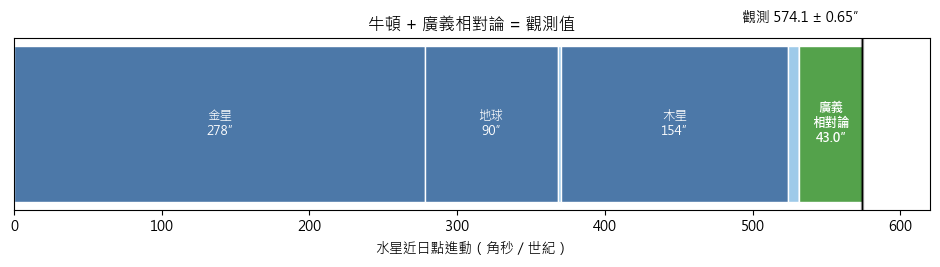

牛頓 531.63 + 廣義相對論 42.98 = 574.61″／世紀
觀測：574.1 ± 0.65″／世紀 → 差 +0.51″，在誤差範圍內


In [8]:
LITERATURE = {"金星": 277.856, "地球": 90.038, "火星": 2.536, "木星": 153.584, "土星": 7.302, "天王星": 0.141, "海王星": 0.042}
newton_total = 531.63          # 牛頓（所有行星 + 太陽扁率等小項），見 01
gr = formula
observed, obs_err = 574.10, 0.65

fig, ax = plt.subplots(figsize=(9.5, 2.8))
left = 0
for name, val in LITERATURE.items():
    ax.barh(0, val, left=left, color="#4c78a8" if val > 20 else "#9ecae9", edgecolor="white")
    if val > 20:
        ax.text(left + val / 2, 0, f"{name}\n{val:.0f}″", ha="center", va="center", color="white", fontsize=9)
    left += val
ax.barh(0, gr, left=newton_total, color="#54a24b", edgecolor="white")
ax.text(newton_total + gr / 2, 0, f"廣義\n相對論\n{gr:.1f}″", ha="center", va="center", color="white", fontsize=9, weight="bold")
ax.axvspan(observed - obs_err, observed + obs_err, color="k", alpha=0.25)
ax.axvline(observed, color="k", lw=1)
ax.text(observed, 0.5, f"觀測 {observed} ± {obs_err}″ ", ha="right", va="bottom")
ax.set_xlim(0, 620)
ax.set_yticks([])
ax.set_xlabel("水星近日點進動（角秒／世紀）")
ax.set_title("牛頓 + 廣義相對論 = 觀測值")
plt.tight_layout()
plt.show()

print(f"牛頓 {newton_total} + 廣義相對論 {gr:.2f} = {newton_total + gr:.2f}″／世紀")
print(f"觀測：{observed} ± {obs_err}″／世紀 → 差 {newton_total + gr - observed:+.2f}″，在誤差範圍內")

**牛頓力學留下的缺口，被廣義相對論剛好補上**，沒有任何可以調整的參數。這就是 1915 年愛因斯坦算出這個數字時興奮到心悸的原因。

**為什麼會進動？** 從比奈方程式看，多出來的項正比於 $u^2 = 1/r^2$，代表引力在近距離時比 $1/r^2$ **再強一點點**。
01 實驗 3 說過：只要力偏離平方反比，Runge–Lenz 向量就會轉，橢圓就會進動。01 的練習 3 問「要偏離多少才能解釋 43″」，答案就藏在這一項裡。

## 實驗 5：光線偏折，1919 年日食

光經過太陽旁邊時會被彎曲。光的軌道方程式（史瓦西時空的「零測地線」）是：

$$\frac{d^2u}{d\varphi^2} + u = \frac{3GM}{c^2}u^2$$

如果沒有右邊，解就是直線。從光最靠近太陽的那一點出發，數值積分到無限遠，看光轉了多少角度：

In [9]:
M_sun = 1.98847e30
R_sun = 6.957e8
GM_SI = G * M_sun


def deflection(b):
    # 從最近點（u = 1/b，du/dφ = 0）積分到 u = 0（無限遠），偏折角 = 2φ_end − π
    rhs = lambda phi, y: [y[1], -y[0] + 3 * GM_SI / c**2 * y[0] ** 2]
    escape = lambda phi, y: y[0]
    escape.terminal, escape.direction = True, -1
    sol = solve_ivp(rhs, [0, np.pi], [1 / b, 0], method="DOP853", rtol=1e-13, atol=1e-25, events=escape)
    return 2 * sol.t_events[0][0] - np.pi


d_num = deflection(R_sun)
d_gr = 4 * GM_SI / (c**2 * R_sun)
print(f"數值積分：     {d_num * ARCSEC:.4f}″")
print(f"廣義相對論公式 4GM/(c²b)：{d_gr * ARCSEC:.4f}″")
print(f"牛頓（把光當成粒子，1801 年 Soldner）：{d_gr / 2 * ARCSEC:.4f}″")

數值積分：     1.7513″
廣義相對論公式 4GM/(c²b)：1.7512″
牛頓（把光當成粒子，1801 年 Soldner）：0.8756″


**擦過太陽邊緣的星光會偏折 1.75″**，剛好是「把光當成有質量的粒子、用牛頓力學算」的**兩倍**。
多出來的那一倍，來自實驗 1 說的「空間也彎曲」：牛頓只有時間項的效果，廣義相對論的空間項又貢獻了一樣多。

**1919 年 5 月 29 日的日全食**：平常看不到太陽旁邊的星星，日全食時才看得到。
愛丁頓帶隊到非洲普林西比島和巴西索布拉爾拍照，和半年前夜晚拍的同一片星空比較：

| 觀測地點 | 量到的偏折 |
|---|---|
| 索布拉爾 | 1.98 ± 0.12″ |
| 普林西比 | 1.61 ± 0.30″ |
| 牛頓預測 | 0.87″ |
| 廣義相對論預測 | 1.75″ |

結果支持愛因斯坦。隔天《紐約時報》頭條：「天上的光都歪了」，愛因斯坦從此家喻戶曉。
今天用電波望遠鏡觀測遙遠類星體，已經把廣義相對論的預測驗證到萬分之一的精確度。

## 實驗 6：黑洞附近的軌道與光線

太陽的 $r_s$ 只有 3 公里，水星在 5800 萬公里外，所以效應很小。如果靠近一個黑洞到只有幾倍 $r_s$ 的距離，廣義相對論效應就變得非常戲劇化。

用 $r_s = 1$ 當長度單位（$GM = 1/2$，$c = 1$）：

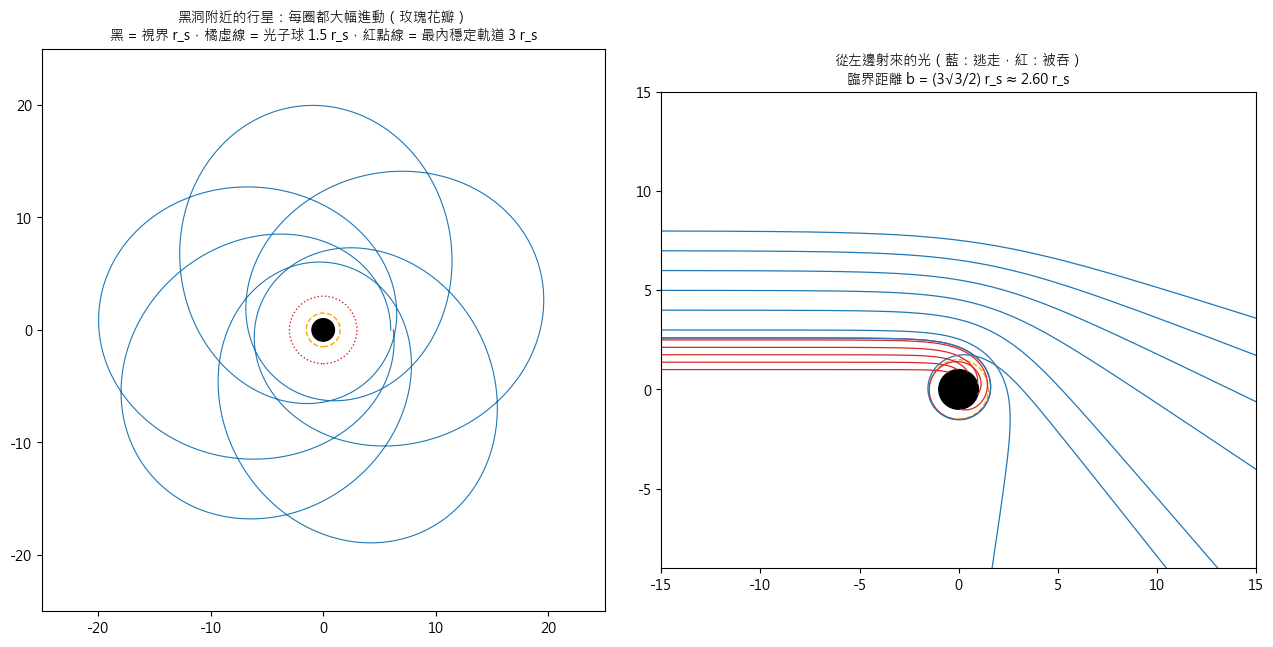

In [10]:
GMb = 0.5     # r_s = 2GM/c² = 1


def bh_orbit(r_peri, h, turns=6):
    rhs = lambda phi, y: [y[1], GMb / h**2 - y[0] + 3 * GMb * y[0] ** 2]
    plunge = lambda phi, y: y[0] - 1.0          # 掉進視界 u = 1/r_s = 1
    plunge.terminal = True
    phi = np.linspace(0, turns * 2 * np.pi, 20000)
    sol = solve_ivp(rhs, [0, phi[-1]], [1 / r_peri, 0], t_eval=phi, method="DOP853", rtol=1e-11, events=plunge)
    r_ = 1 / sol.y[0]
    return r_ * np.cos(sol.t), r_ * np.sin(sol.t)


def photon_path(b, r0=30.0):
    # 從很遠的左邊射來、和中心的垂直距離為 b 的光
    phi0 = np.pi - np.arcsin(b / r0)
    rhs = lambda phi, y: [y[1], -y[0] + 3 * GMb * y[0] ** 2]
    captured = lambda phi, y: y[0] - 1.0
    captured.terminal = True
    gone = lambda phi, y: y[0] - 1 / (1.05 * r0)     # 飛回比起點更遠 → 已經離開
    gone.terminal, gone.direction = True, -1
    sol = solve_ivp(rhs, [phi0, phi0 - 4 * np.pi], [1 / r0, np.cos(phi0) / b],
                    max_step=0.01, rtol=1e-10, events=[captured, gone])
    r_ = 1 / sol.y[0]
    return r_ * np.cos(sol.t), r_ * np.sin(sol.t)


fig, axes = plt.subplots(1, 2, figsize=(13, 6.3))
ax = axes[0]
# 近點 6、遠點 20 的軌道：由首次積分 (u′)² + u² − r_s u³ − (r_s/h²) u = 常數，在兩個轉折點相等，反解出 h
u1, u2 = 1 / 6, 1 / 20
h_orbit = np.sqrt(1 / ((u1 + u2) - (u1**2 + u1 * u2 + u2**2)))
xo, yo = bh_orbit(r_peri=6.0, h=h_orbit)
ax.plot(xo, yo, lw=0.8)
ax.add_patch(plt.Circle((0, 0), 1, color="k"))
ax.add_patch(plt.Circle((0, 0), 1.5, color="orange", fill=False, ls="--", lw=1))
ax.add_patch(plt.Circle((0, 0), 3, color="C3", fill=False, ls=":", lw=1))
ax.set_aspect("equal")
ax.set_xlim(-25, 25)
ax.set_ylim(-25, 25)
ax.set_title("黑洞附近的行星：每圈都大幅進動（玫瑰花瓣）\n黑 = 視界 r_s，橘虛線 = 光子球 1.5 r_s，紅點線 = 最內穩定軌道 3 r_s", fontsize=10)

ax = axes[1]
b_crit = 3 * np.sqrt(3) / 2
for b in np.concatenate([np.linspace(1.0, 2.5, 5), [b_crit - 0.001, b_crit + 0.001], np.linspace(3.0, 8.0, 6)]):
    xp, yp = photon_path(b)
    color = "C3" if b < b_crit else "C0"
    ax.plot(xp, yp, color=color, lw=0.9)
ax.add_patch(plt.Circle((0, 0), 1, color="k"))
ax.add_patch(plt.Circle((0, 0), 1.5, color="orange", fill=False, ls="--", lw=1))
ax.set_aspect("equal")
ax.set_xlim(-15, 15)
ax.set_ylim(-9, 15)
ax.set_title(f"從左邊射來的光（藍：逃走，紅：被吞）\n臨界距離 b = (3√3/2) r_s ≈ {b_crit:.2f} r_s", fontsize=10)
plt.tight_layout()
plt.show()

**觀察**：

- **左圖**：黑洞附近的軌道每一圈轉了一大截，畫出玫瑰花瓣。水星的進動是同一個效應，只是小了一千萬倍。
- 黑洞附近有兩個牛頓力學沒有的特殊半徑：
  - **最內穩定圓軌道**（3 $r_s$）：再靠近就沒有穩定的圓軌道，物質會螺旋掉進去。黑洞周圍的吸積盤內緣就在這裡。
  - **光子球**（1.5 $r_s$）：光可以在這裡繞圈（但不穩定）。
- **右圖**：光經過黑洞會偏折；太靠近（$b$ 小於臨界值）就被吞掉。剛好在臨界值附近的光會**繞黑洞好幾圈**才離開或掉進去。
  2019 年事件視界望遠鏡拍到的第一張黑洞照片，中間那個暗區的大小就是這個臨界值決定的。

## 總結

| 實驗 | 結果 | 對照 |
|---|---|---|
| 史瓦西度規 | sympy 證明 $R_{\mu\nu} = 0$ | 改錯的度規 ≠ 0 |
| 奇異點 | 視界是座標假象，中心曲率真的無限大 | 廣義相對論預告自己失效 |
| GPS | 衛星鐘每天快 38.5 μs | 衛星出廠設定，差 < 0.3% |
| 水星 | 42.98″／世紀 | 牛頓 531.6 + 43.0 = 574.6，觀測 574.1 ± 0.65 |
| 光線偏折 | 1.75″ | 1919 日食 1.98 ± 0.12″；牛頓只有一半 |
| 黑洞 | 玫瑰花瓣軌道、光子球、黑洞陰影 | 2019 事件視界望遠鏡 |

**牛頓的兩個假設都已經拆掉了**：絕對時間（03）和瞬間作用的引力（這裡）。時空本身是動態的、彎曲的。

**但廣義相對論保留了牛頓的另一個假設：確定性。** 度規在每一點都有確定的值，物質在確定的位置。
而量子力學說物質沒有確定的位置。愛因斯坦方程式的右邊放不進量子物質，左邊的時空又是古典的。這就是 05 要面對的事。

下一本（04-2）先看一個廣義相對論最壯觀的預言：**時空本身的波動**。

## 練習

1. 實驗 4：把水星換成地球（$a = 1$、$e = 0.0167$），地球每世紀因廣義相對論進動多少？（觀測值約 3.8″。）
2. 實驗 5：如果星光擦過**木星**邊緣（質量 $1.9\times10^{27}$ kg，半徑 $7.15\times10^7$ m），偏折多少？
3. 實驗 3：國際太空站（高 420 km）上的鐘，比地面快還是慢？算算看重力和速度哪個贏。